<p><a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a></p>

<p><a href="https://query.farm/vgi/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/vgi-logo.png" alt="VGI" width="112"></a></p>

# [Terrain analysis](https://github.com/Query-farm/vgi-terrain)

DEM visibility, viewsheds, slope and aspect from SQL.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Query-farm/vgi-terrain/blob/main/notebooks/02_paginated_inventory_report.ipynb)

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Example notes](https://github.com/Query-farm/vgi-terrain/blob/main/notebooks/README.md)


## 02 · Complete the input before previewing a report

**Which illustrative equipment items are individually affordable, and have we retrieved every page before answering?** This separate workflow uses the worker's public `examples` schema: an API reader, a deterministic sequence generator and a greeting formatter. None performs terrain analysis or validates real procurement decisions.

A local loopback server supplies six **authored synthetic items and USD prices**, split across three pages. A generated budget grid compares affordable-item counts. Finally, local report previews preserve missing reviewer names instead of inventing recipients. No real API, account, credential or message is used.

### Choose a per-item budget

`BUDGET_USD` is an integer from **0 to 150 in increments of 25**; default **50**, experiment **75**. An item is affordable when its price is at most the budget. Each comparison buys one item independently: this is not a basket optimization or a recommended equipment list. Prices, pagination and all seven budget scenarios stay fixed.

In [1]:
BUDGET_USD = 50

In [2]:
import importlib.metadata as packages
import sys

installed = {d.metadata["Name"]: d.version for d in packages.distributions()}
if installed.get("vgi-example-notebooks") != "0.3.26":
    %pip install -q "git+https://github.com/Query-farm/vgi-example-notebooks@v0.3.26"
    if "vgi_notebooks" in sys.modules:
        raise RuntimeError("Restart the kernel, then run all cells.")

from vgi_notebooks import check_runtime  # noqa: E402

check_runtime()

In [3]:
if type(BUDGET_USD) is not int or not 0 <= BUDGET_USD <= 150 or BUDGET_USD % 25:
    raise ValueError("BUDGET_USD must be an integer from 0 to 150 in increments of 25.")
from vgi_notebooks import connect, prepare
from vgi_notebooks.presentation import finish, prose, theme
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display

prepare("terrain")
theme()
session = connect(globals())

from terrain_fixture import SyntheticInventory  # noqa: E402

fixture = SyntheticInventory()
SOURCE = "Source: six authored synthetic equipment prices · loopback fixture · vgi-terrain v0.1.0 examples schema"

### Connect to the released worker

The literal Git-tag launcher starts published **v0.1.0** in an isolated Python 3.13 environment. The release owns its dependency constraints; no extra SDK override or local source checkout is needed. The notebook installs the shared base package; the local publication environment adds `[runner]`. First use needs package, Git and VGI extension downloads. The shared connection disables persistent SQL secrets and starts with an empty temporary secret directory.

The worker has two public schemas: `main` contains terrain analysis, while `examples` retains generic starter recipes. Schema qualification is deliberate: examples are not additional terrain models.

The fixture temporarily clears the worker's optional API-token environment variable, rejects Authorization headers and serves only its local items route. It restores the previous environment during cleanup without displaying it. No SQL secret is created. The shared connection's empty secret directory also prevents an unrelated saved secret from being selected.

In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'terrain' (TYPE vgi,
 LOCATION 'uvx --python 3.13 --from git+https://github.com/Query-farm/vgi-terrain@v0.1.0 vgi-terrain-worker');

,Success


### Materialize the complete paginated read once

The real worker follows `next_page` until it reaches the end. `page_size=2` means three requests for six authored items. Materialize the API call before display so JupySQL cannot fetch twice while capturing a DataFrame. The API's floating-point prices are converted to exact two-decimal SQL values before monetary comparisons.

In [5]:
%%sql inventory <<
CREATE TABLE raw_items AS SELECT * FROM terrain.examples.fetch_items('{{ fixture.base_url }}',page_size:=2);
CREATE TABLE items AS SELECT id,name,category,price::DECIMAL(10,2) AS price_usd FROM raw_items;
SELECT id,name,category,price_usd,price_usd<={{ BUDGET_USD }} AS affordable FROM items ORDER BY price_usd,id;

In [6]:
display(inventory)
request_audit = fixture.requests
assert request_audit == [
    {"page": 1, "page_size": 2, "item_ids": [101, 102], "credential_present": False},
    {"page": 2, "page_size": 2, "item_ids": [103, 104], "credential_present": False},
    {"page": 3, "page_size": 2, "item_ids": [105, 106], "credential_present": False},
]
display(request_audit)
prose(
    f"All **{len(inventory)} items** arrived through **{len(request_audit)} requests**. At **${BUDGET_USD} per item**, **{int(inventory.affordable.sum())} items** qualify. This count would be wrong if only the first page were retained."
)

,id,name,category,price_usd,affordable
0,101,Hand level,survey,20.0,True
1,102,Field notebook,supplies,35.0,True
2,103,Rangefinder,survey,50.0,True
3,104,Tripod,mounting,75.0,False
4,105,Receiver,electronics,100.0,False
5,106,Protective case,supplies,140.0,False


[{'page': 1,
  'page_size': 2,
  'item_ids': [101, 102],
  'credential_present': False},
 {'page': 2,
  'page_size': 2,
  'item_ids': [103, 104],
  'credential_present': False},
 {'page': 3,
  'page_size': 2,
  'item_ids': [105, 106],
  'credential_present': False}]

All **6 items** arrived through **3 requests**. At **$50 per item**, **3 items** qualify. This count would be wrong if only the first page were retained.

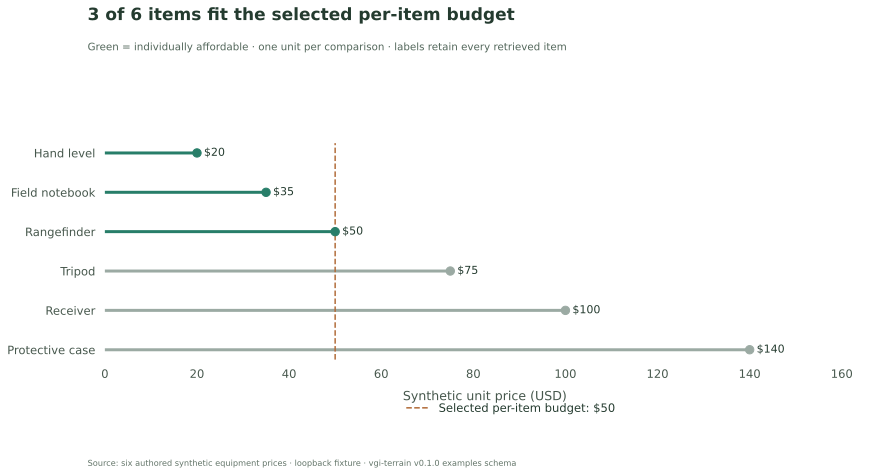

In [7]:
fig, ax = plt.subplots(figsize=(12, 7))
y = np.arange(len(inventory))
colors = np.where(inventory.affordable, "#287E69", "#9BAAA3")
ax.hlines(y, 0, inventory.price_usd, color=colors, linewidth=3)
ax.scatter(inventory.price_usd, y, color=colors, s=70, zorder=3)
ax.axvline(
    BUDGET_USD, color="#B16B39", linestyle="--", label=f"Selected per-item budget: ${BUDGET_USD}"
)
for i, row in enumerate(inventory.itertuples()):
    ax.annotate(
        f"${row.price_usd:.0f}",
        (row.price_usd, i),
        xytext=(7, 0),
        textcoords="offset points",
        va="center",
    )
ax.set(yticks=y, yticklabels=inventory.name, xlabel="Synthetic unit price (USD)", xlim=(0, 165))
ax.invert_yaxis()
fig.legend(loc="lower center", bbox_to_anchor=(0.56, 0.14))
finish(
    fig,
    f"{int(inventory.affordable.sum())} of 6 items fit the selected per-item budget",
    "Green = individually affordable · one unit per comparison · labels retain every retrieved item",
    SOURCE,
    name=f"inventory-budget-{BUDGET_USD}",
)

### Generate comparison budgets, then join to the inventory

`sequence_table(7, step:=25)` produces 0, 25, …, 150. Its `squared` output is a generic generator feature, not a cost model, and is not used here. SQL joins every generated budget to the same complete inventory. These are sampled budget scenarios; the connecting line is omitted so no extra price threshold is implied between them.

In [8]:
%%sql budget_grid <<
CREATE TABLE budget_grid AS
SELECT s.n AS budget_usd,count(i.id) AS affordable_items
FROM terrain.examples.sequence_table(7,step:=25) s
LEFT JOIN items i ON i.price_usd<=s.n GROUP BY s.n;
SELECT * FROM budget_grid ORDER BY budget_usd;

,budget_usd,affordable_items
0,0,0
1,25,1
2,50,3
3,75,4
4,100,5
5,125,5
6,150,6


The generator supplies **7 fixed scenarios**, including a zero budget with no affordable items. The selected **$50** scenario agrees with the item-level filter. Increasing the budget changes affordability, not the input population.

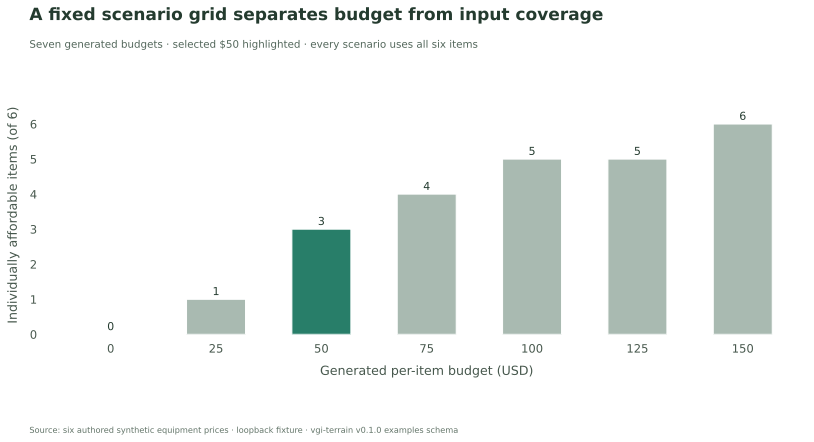

In [9]:
display(budget_grid)
prose(
    f"The generator supplies **{len(budget_grid)} fixed scenarios**, including a zero budget with no affordable items. The selected **${BUDGET_USD}** scenario agrees with the item-level filter. Increasing the budget changes affordability, not the input population."
)
fig, ax = plt.subplots(figsize=(12, 6.5))
colors = ["#287E69" if x == BUDGET_USD else "#A9BAB1" for x in budget_grid.budget_usd]
ax.bar(budget_grid.budget_usd, budget_grid.affordable_items, width=14, color=colors)
for row in budget_grid.itertuples():
    ax.text(row.budget_usd, row.affordable_items + 0.12, str(row.affordable_items), ha="center")
ax.set(
    xlabel="Generated per-item budget (USD)",
    ylabel="Individually affordable items (of 6)",
    xticks=budget_grid.budget_usd,
    yticks=range(7),
    ylim=(0, 6.8),
)
finish(
    fig,
    "A fixed scenario grid separates budget from input coverage",
    f"Seven generated budgets · selected ${BUDGET_USD} highlighted · every scenario uses all six items",
    SOURCE,
    name=f"budget-grid-{BUDGET_USD}",
)

### Preview report text without inventing a reviewer

The `greet` scalar formats a name; it does not resolve an identity or deliver a message. Use its casual and formal overloads over two synthetic names plus SQL NULL. A missing name must remain unavailable. We construct a preview only for known names and leave the third preview NULL; this is local table output, not a send action.

In [10]:
%%sql previews <<
CREATE TABLE reviewers AS SELECT * FROM (VALUES (1,'Ada'),(2,'Sam'),(3,NULL)) r(reviewer_id,reviewer_name);
CREATE TABLE report_previews AS
SELECT reviewer_id,reviewer_name,terrain.examples.greet(reviewer_name) AS casual_greeting,
 terrain.examples.greet(reviewer_name,'formal') AS formal_greeting,
 CASE WHEN reviewer_name IS NOT NULL THEN terrain.examples.greet(reviewer_name,'formal')
  || ' At ${{ BUDGET_USD }} per item, ' || (SELECT affordable_items FROM budget_grid WHERE budget_usd={{ BUDGET_USD }})
  || ' of 6 synthetic items qualify.' END AS preview
FROM reviewers;
SELECT * FROM report_previews ORDER BY reviewer_id;

In [11]:
display(previews.drop(columns="preview"))
for row in previews.itertuples():
    text = row.preview if isinstance(row.preview, str) else "Unavailable: reviewer name is NULL."
    prose(f"**Local preview {row.reviewer_id}:** {text}")
prose(
    f"There are **{int(previews.preview.notna().sum())} local report previews** and **{int(previews.preview.isna().sum())} missing-name row**. Formal and casual greetings are formatting choices; neither establishes an identity. No messages are sent."
)

,reviewer_id,reviewer_name,casual_greeting,formal_greeting
0,1,Ada,"Hi, Ada!","Good day, Ada."
1,2,Sam,"Hi, Sam!","Good day, Sam."
2,3,None,None,None


**Local preview 1:** Good day, Ada. At $50 per item, 3 of 6 synthetic items qualify.

**Local preview 2:** Good day, Sam. At $50 per item, 3 of 6 synthetic items qualify.

**Local preview 3:** Unavailable: reviewer name is NULL.

There are **2 local report previews** and **1 missing-name row**. Formal and casual greetings are formatting choices; neither establishes an identity. No messages are sent.

### Verify completeness and distinct responsibilities

Check the fixed input IDs, exact prices, selected scenario and NULL handling. The request audit above is independent of the SQL row count: six rows alone cannot prove that a stateful call was not repeated. No checks require live credentials.

In [12]:
%%sql checks <<
SELECT 'complete unique fixed inventory' AS check_name,count(*)=6 AND count(DISTINCT id)=6 AND min(id)=101 AND max(id)=106 AS passed FROM items
UNION ALL SELECT 'authored price total',sum(price_usd)=420.00 AND min(price_usd)=20 AND max(price_usd)=140 FROM items
UNION ALL SELECT 'seven fixed budget scenarios',count(*)=7 AND min(budget_usd)=0 AND max(budget_usd)=150 FROM budget_grid
UNION ALL SELECT 'selected count reconciles',(SELECT affordable_items FROM budget_grid WHERE budget_usd={{ BUDGET_USD }})=count(*) FROM items WHERE price_usd<={{ BUDGET_USD }}
UNION ALL SELECT 'monotone scenario counts',bool_and(affordable_items>=previous_count) FROM (SELECT affordable_items,lag(affordable_items,1,0) OVER(ORDER BY budget_usd) previous_count FROM budget_grid)
UNION ALL SELECT 'missing name stays missing',count(*)=1 AND bool_and(casual_greeting IS NULL AND formal_greeting IS NULL AND preview IS NULL) FROM report_previews WHERE reviewer_name IS NULL
UNION ALL SELECT 'two known report previews',count(*)=2 AND bool_and(casual_greeting='Hi, '||reviewer_name||'!' AND formal_greeting='Good day, '||reviewer_name||'.' AND preview IS NOT NULL) FROM report_previews WHERE reviewer_name IS NOT NULL;

In [13]:
display(checks)
assert checks.passed.fillna(False).all()
assert session.connection.execute("SELECT * FROM duckdb_secrets()").fetchall() == []

,check_name,passed
0,complete unique fixed inventory,True
1,authored price total,True
2,seven fixed budget scenarios,True
3,selected count reconciles,True
4,monotone scenario counts,True
5,missing name stays missing,True
6,two known report previews,True


### Experiment: change the decision, not the input

Change only **`BUDGET_USD` from 50 to 75** using the separate output directory documented in the README. Predict one additional affordable item. The six IDs, three request pages, price table, seven scenario counts and missing-reviewer row must stay fixed. The chosen bar, item affordability and two preview texts change.

This notebook demonstrates the starter schema's transport, generation and formatting contracts. It supplies no terrain measurements and no purchasing or field-safety recommendation.

In [14]:
session.close()
fixture.close()
plt.close("all")

<a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Worker repository: vgi-terrain](https://github.com/Query-farm/vgi-terrain)
